# THeatA surface-code prior calibration

This notebook runs the complete experiment through the same modules as the CLI:
standard Stim circuit → THeatA native compilation → actual noisy model →
independent calibration/test samples → exact covariance and boundary inversion
→ paired MWPM evaluation → two LER figures.

The inferred parameters are the **identifiable edge priors of the memory-sector
marginal DEM**. The full circuit DEM may contain cross-sector hyperedges.
Identifying their separate priors from first and second moments depends on
the known support matrix; that general rank analysis is documented separately.
This implementation validates the exact projection and known logical labels.

Reference: [Chen et al. (2021), Supplement VI.1, S11 and S14–S16](https://arxiv.org/html/2102.06132v1).
See `docs/method.md` for the complete assumptions and sampling definitions.


## 1. Configuration

Run `bash scripts/bootstrap.sh` first and select the THeatA prior calibration
kernel. `THEATA_PATH` can select an existing checkout. This walkthrough uses
`configs/main1.yaml` and saves results in `results/main1`. Set `CONFIG` to
`configs/smoke.yaml` for a short execution check. The output directory
follows the configuration filename.
The physical rate p is the mean total nonidentity MS-gate error probability.


In [1]:
import json
import os
from pathlib import Path
import sys

candidates = [Path(os.environ.get('THEATA_PRIOR_PROJECT', '.')).resolve(), Path.cwd().resolve(), Path.cwd().resolve().parent]
ROOT = next((p for p in candidates if (p / 'pyproject.toml').exists() and (p / 'src/theata_prior').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook within the extracted theata-prior-calibration project.')
sys.path.insert(0, str(ROOT / 'src'))

from theata_prior.config import load_config
from theata_prior.experiment import build_models, sample_models, fit_models, evaluate_models_stage, fit_directory
from theata_prior.plotting import plot_results
from theata_prior.io import read_json

CONFIG = ROOT / 'configs/main1.yaml'
OUT = ROOT / 'results' / CONFIG.stem
config = load_config(CONFIG)
print(json.dumps(config.to_dict(), indent=2))


{
  "distances": [
    3,
    5,
    7,
    9
  ],
  "basis": "z",
  "rounds_per_distance": 1,
  "physical_error_rates": [
    0.0005,
    0.001,
    0.002,
    0.004
  ],
  "training_shots": [
    1000,
    10000,
    50000,
    100000
  ],
  "test_shots": 100000,
  "repetitions": 1,
  "seed": 20261126,
  "sample_source": "dem",
  "workers": 8,
  "sample_chunk_shots": 16384,
  "decode_chunk_shots": 8192,
  "covariance_chunk_shots": 8192,
  "covariance_block_detectors": 128,
  "probability_floor": 1e-08,
  "probability_ceiling": 0.499999,
  "strict_estimation": false,
  "theata_path": "vendor/theata",
  "hardware": {
    "compiler_options": {
      "cool_threshold_transversal": 1.5
    },
    "strict_lut": true
  }
}


## 2. Compile the standard circuit and construct the known structure

The compiler keeps all original Stim data and ancilla qubits. Exact native
Clifford identities and the upstream sequential/parallel hardware validators
are checked. The supplied YAML enables threshold cooling and rejects any MS
lookup beyond the tabulated phonon range.


In [2]:
case_list = build_models(config, OUT)
case = case_list[-1]
hardware = read_json(case.directory / 'hardware.json')
model = read_json(case.directory / 'model.json')
print(json.dumps({k: model[k] for k in ['distance', 'rounds', 'physical_error_rate', 'full_detectors', 'sector_detectors', 'sector_errors']}, indent=2))
print('Mean physical MS error:', hardware['mean_ms_error'])
print('THeatA duration [s]:', hardware['duration_us'] / 1e6)
print('Compiled noisy circuit, first instructions:')
print('\n'.join((case.directory / 'actual_noisy.stim').read_text().splitlines()[:18]))


build: d=3 cached


build: d=5 cached


build: d=7 cached


build: d=9 cached


{
  "distance": 9,
  "rounds": 9,
  "physical_error_rate": 0.004,
  "full_detectors": 720,
  "sector_detectors": 400,
  "sector_errors": 1945
}
Mean physical MS error: 0.003999999999999998
THeatA duration [s]: 156.10656700001175
Compiled noisy circuit, first instructions:
QUBIT_COORDS(1, 1) 1
QUBIT_COORDS(2, 0) 2
QUBIT_COORDS(3, 1) 3
QUBIT_COORDS(5, 1) 5
QUBIT_COORDS(6, 0) 6
QUBIT_COORDS(7, 1) 7
QUBIT_COORDS(9, 1) 9
QUBIT_COORDS(10, 0) 10
QUBIT_COORDS(11, 1) 11
QUBIT_COORDS(13, 1) 13
QUBIT_COORDS(14, 0) 14
QUBIT_COORDS(15, 1) 15
QUBIT_COORDS(17, 1) 17
QUBIT_COORDS(1, 3) 20
QUBIT_COORDS(2, 2) 21
QUBIT_COORDS(3, 3) 22
QUBIT_COORDS(4, 2) 23
QUBIT_COORDS(5, 3) 24


## 3. Sample calibration and independent heldout data

The default source is the full actual **independent DEM**, with selected
detectors and all logical flips retained. `sample_source: circuit` instead
samples the compiled physical circuit and includes circuit-to-independent-DEM
model mismatch. Logical labels are never used for prior fitting.

Each training size N takes the first N rows of a single maximum-size training
dataset. Test data use a different random namespace and are shared by all
compared decoders. Worker count can change without changing samples for fixed
shard size, source and Stim build.


In [3]:
sample_models(config, OUT)
from theata_prior.sampling import SampleSet
train = SampleSet.open(case.directory / 'samples_train_000', validate_observables=False)
test = SampleSet.open(case.directory / 'samples_test')
print('Calibration detectors:', train.load_detectors().shape)
print('Heldout detectors:', test.load_detectors().shape)
print('Heldout logical flips:', test.load_observables().shape)
assert train.metadata['config']['stream'] != test.metadata['config']['stream']


sample: d=3 p=0.0005; train=100000 x 1, test=100000


sample: d=3 p=0.001; train=100000 x 1, test=100000


sample: d=3 p=0.002; train=100000 x 1, test=100000


sample: d=3 p=0.004; train=100000 x 1, test=100000


sample: d=5 p=0.0005; train=100000 x 1, test=100000


sample: d=5 p=0.001; train=100000 x 1, test=100000


... (7 outputs left out)

sample: d=9 p=0.001; train=100000 x 1, test=100000


sample: d=9 p=0.002; train=100000 x 1, test=100000


sample: d=9 p=0.004; train=100000 x 1, test=100000


Calibration detectors: (100000, 400)
Heldout detectors: (100000, 400)
Heldout logical flips: (100000, 1)


## 4. Estimate mechanism priors

For $\mu_i=\langle x_i\rangle$ and $\mu_{ij}=\langle x_i x_j\rangle$, the exact
pair inversion is

$$\widehat p_{ij}=\frac12\left(1-\sqrt{
\frac{(1-2\mu_i)(1-2\mu_j)}{1-2\mu_i-2\mu_j+4\mu_{ij}}}\right).$$

Let $e$ index known mechanisms, $q_e$ be their priors, and $H_{ie}=1$ mean
that mechanism $e$ flips detector $i$. With $a_e=-\log(1-2q_e)$, define
$\widetilde P_{ij}=p_{ij}$ off the diagonal and $\widetilde P_{ii}=\mu_i$.
The entrywise transformation

$$\Gamma_{ij}=-\log(1-2\widetilde P_{ij})$$

gives the unified real-valued equation

$$\Gamma=H\operatorname{diag}(a)H^\top
=\sum_e a_e h_eh_e^\top.$$

In the implemented graphlike model, a mechanism with support $S_e=\{i,j\}$
has $q_e=p_{ij}$. For $S_e=\{i\}$, the diagonal equation isolates its prior:

$$q_e=\frac12\left[
1-\frac{1-2\mu_i}
{\prod_{\substack{f\ne e\\H_{if}=1}}(1-2q_f)}
\right].$$

This is S14--S16 expressed using the general mechanism index $e$.
See the [general derivation](../docs/general_prior_derivation.md) for the
step-by-step proof and the rank condition for arbitrary known supports.

The implementation uses stable equivalent forms. The full raw $p_{ij}$ matrix
retains negative finite-sample estimates; only known decoder edges are clipped
to the configured fixed interval. Boundary estimates use the regularized
incident pair priors. Diagnostics record all interventions.

S11 requires empirical detector means below 1/2. The notebook records fits
outside this range as undefined and continues with the available fits.


In [4]:
fit_models(config, OUT, skip_saturated_marginals=True)
import numpy as np
from theata_prior.dem import GraphStructure

fit_dir = fit_directory(case, rep=0, shots=max(config.training_shots))
structure = GraphStructure.from_dict(read_json(case.directory / 'known_structure.json'))
if (fit_dir / 'fit_complete.json').is_file():
    p_ij = np.load(fit_dir / 'p_ij.npy')
    fitted_priors = np.load(fit_dir / 'estimated_priors.npy')
    moments = np.load(fit_dir / 'moments.npz')
    print('p_ij matrix shape:', p_ij.shape)
    print('Diagnostics:')
    print(json.dumps(read_json(fit_dir / 'diagnostics.json'), indent=2)[:7000])
    print('Estimated DEM, first edges:')
    print('\n'.join((fit_dir / 'estimated.dem').read_text().splitlines()[:10]))
else:
    print('The selected fit is undefined. See fit_skips.json after evaluation.')


fit: d=9 p=0.004 N=1000 rep=0; undefined with 40 detector means >= 1/2


p_ij matrix shape: (400, 400)
Diagnostics:
{
  "method": "S11_exact_pairs_S14_S15_S16_boundaries",
  "calibration_shots": 100000,
  "probability_floor": 1e-08,
  "probability_ceiling": 0.499999,
  "strict": false,
  "pairs": {
    "total": 1845,
    "nonfinite": 304,
    "negative": 181,
    "at_or_above_half": 0,
    "below_probability_floor": 181,
    "above_probability_ceiling": 0,
    "regularized": 485
  },
  "boundaries": {
    "total": 100,
    "nonfinite": 0,
    "negative": 12,
    "at_or_above_half": 0,
    "below_probability_floor": 12,
    "above_probability_ceiling": 0,
    "regularized": 12
  },
  "all_known_edges": {
    "total": 1945,
    "nonfinite": 304,
    "negative": 193,
    "at_or_above_half": 0,
    "below_probability_floor": 193,
    "above_probability_ceiling": 0,
    "regularized": 497
  },
  "full_matrix_negative_offdiagonal": 26384,
  "full_matrix_invalid_offdiagonal": 13009,
  "maximum_absolute_nonedge_estimate": 3126116.8090801965,
  "max_marginal_residua

## 5. Paired MWPM evaluation

Both actual and inferred decoders use the same graph and logical edge labels.
Logical failure means at least one predicted observable differs from the
heldout label, per complete memory experiment. Reported Wilson intervals are
conditional on each calibration dataset. Paired differences use discordant
failure counts, not an independence assumption between decoders.


In [5]:
rows = evaluate_models_stage(config, OUT, skip_saturated_marginals=True)
from IPython.display import Markdown, display

header = '| d | p | Calibration N | Decoder | Failures / test shots | LER | 95% Wilson interval |\n|---|---|---|---|---|---|---|\n'
body = '\n'.join(f"| {r['distance']} | {r['physical_error_rate']:g} | {r['calibration_shots'] or 'actual'} | {r['decoder']} | {r['failures']} / {r['shots']} | {r['logical_error_rate']:.6g} | [{r['ci_low']:.6g}, {r['ci_high']:.6g}] |" for r in rows)
display(Markdown(header + body))
for fit in read_json(OUT / 'fit_skips.json'):
    display(Markdown(
        f"**Undefined S11 fit** for d={fit['distance']}, p={fit['physical_error_rate']:g}, "
        f"N={fit['calibration_shots']:,}, repetition {fit['repetition']}. "
        f"{len(fit['saturated_detector_ids'])} detector means reached or exceeded 1/2."
    ))


decode: d=3 p=0.0005; actual LER=0.00111


decode: d=3 p=0.001; actual LER=0.00442


decode: d=3 p=0.002; actual LER=0.01703


decode: d=3 p=0.004; actual LER=0.05707


decode: d=5 p=0.0005; actual LER=0.00687


decode: d=5 p=0.001; actual LER=0.0407


... (8 outputs left out)

decode: d=9 p=0.002; actual LER=0.4995


decode: d=9 p=0.004; actual LER=0.49923


| d | p | Calibration N | Decoder | Failures / test shots | LER | 95% Wilson interval |
|---|---|---|---|---|---|---|
| 3 | 0.0005 | actual | actual | 111 / 100000 | 0.00111 | [0.0009219, 0.00133643] |
| 3 | 0.0005 | 1000 | estimated | 540 / 100000 | 0.0054 | [0.00496439, 0.00587361] |
| 3 | 0.0005 | 10000 | estimated | 235 / 100000 | 0.00235 | [0.00206841, 0.00266982] |
| 3 | 0.0005 | 50000 | estimated | 104 / 100000 | 0.00104 | [0.000858479, 0.00125985] |
| 3 | 0.0005 | 100000 | estimated | 110 / 100000 | 0.0011 | [0.000912827, 0.0013255] |
| 3 | 0.001 | actual | actual | 442 / 100000 | 0.00442 | [0.00402746, 0.00485062] |
| 3 | 0.001 | 1000 | estimated | 479 / 100000 | 0.00479 | [0.00438068, 0.00523737] |
| 3 | 0.001 | 10000 | estimated | 435 / 100000 | 0.00435 | [0.00396071, 0.00477737] |
| 3 | 0.001 | 50000 | estimated | 443 / 100000 | 0.00443 | [0.00403699, 0.00486108] |
| 3 | 0.001 | 100000 | estimated | 445 / 100000 | 0.00445 | [0.00405607, 0.004882] |
| 3 | 0.002 | actual | actual | 1703 / 100000 | 0.01703 | [0.0162464, 0.0178507] |
| 3 | 0.002 | 1000 | estimated | 2085 / 100000 | 0.02085 | [0.0199827, 0.0217542] |
| 3 | 0.002 | 10000 | estimated | 1700 / 100000 | 0.017 | [0.0162171, 0.01782] |
| 3 | 0.002 | 50000 | estimated | 1697 / 100000 | 0.01697 | [0.0161878, 0.0177893] |
| 3 | 0.002 | 100000 | estimated | 1705 / 100000 | 0.01705 | [0.016266, 0.0178711] |
| 3 | 0.004 | actual | actual | 5707 / 100000 | 0.05707 | [0.0556492, 0.0585249] |
| 3 | 0.004 | 1000 | estimated | 5791 / 100000 | 0.05791 | [0.0564792, 0.0593747] |
| 3 | 0.004 | 10000 | estimated | 5731 / 100000 | 0.05731 | [0.0558863, 0.0587677] |
| 3 | 0.004 | 50000 | estimated | 5696 / 100000 | 0.05696 | [0.0555405, 0.0584136] |
| 3 | 0.004 | 100000 | estimated | 5696 / 100000 | 0.05696 | [0.0555405, 0.0584136] |
| 5 | 0.0005 | actual | actual | 687 / 100000 | 0.00687 | [0.00637665, 0.00740124] |
| 5 | 0.0005 | 1000 | estimated | 860 / 100000 | 0.0086 | [0.00804628, 0.00919147] |
| 5 | 0.0005 | 10000 | estimated | 709 / 100000 | 0.00709 | [0.00658857, 0.0076293] |
| 5 | 0.0005 | 50000 | estimated | 692 / 100000 | 0.00692 | [0.0064248, 0.00745308] |
| 5 | 0.0005 | 100000 | estimated | 692 / 100000 | 0.00692 | [0.0064248, 0.00745308] |
| 5 | 0.001 | actual | actual | 4070 / 100000 | 0.0407 | [0.0394929, 0.0419424] |
| 5 | 0.001 | 1000 | estimated | 4828 / 100000 | 0.04828 | [0.0469687, 0.049626] |
| 5 | 0.001 | 10000 | estimated | 4165 / 100000 | 0.04165 | [0.0404292, 0.042906] |
| 5 | 0.001 | 50000 | estimated | 4108 / 100000 | 0.04108 | [0.0398674, 0.0423279] |
| 5 | 0.001 | 100000 | estimated | 4076 / 100000 | 0.04076 | [0.039552, 0.0420033] |
| 5 | 0.002 | actual | actual | 18578 / 100000 | 0.18578 | [0.183382, 0.188203] |
| 5 | 0.002 | 1000 | estimated | 21348 / 100000 | 0.21348 | [0.210951, 0.216031] |
| 5 | 0.002 | 10000 | estimated | 18780 / 100000 | 0.1878 | [0.185391, 0.190233] |
| 5 | 0.002 | 50000 | estimated | 18650 / 100000 | 0.1865 | [0.184098, 0.188926] |
| 5 | 0.002 | 100000 | estimated | 18603 / 100000 | 0.18603 | [0.18363, 0.188454] |
| 5 | 0.004 | actual | actual | 42538 / 100000 | 0.42538 | [0.422319, 0.428447] |
| 5 | 0.004 | 1000 | estimated | 44857 / 100000 | 0.44857 | [0.445489, 0.451654] |
| 5 | 0.004 | 10000 | estimated | 43060 / 100000 | 0.4306 | [0.427534, 0.433672] |
| 5 | 0.004 | 50000 | estimated | 42591 / 100000 | 0.42591 | [0.422848, 0.428978] |
| 5 | 0.004 | 100000 | estimated | 42537 / 100000 | 0.42537 | [0.422309, 0.428437] |
| 7 | 0.0005 | actual | actual | 4474 / 100000 | 0.04474 | [0.0434761, 0.0460389] |
| 7 | 0.0005 | 1000 | estimated | 5842 / 100000 | 0.05842 | [0.0569832, 0.0598907] |
| 7 | 0.0005 | 10000 | estimated | 4552 / 100000 | 0.04552 | [0.0442455, 0.0468295] |
| 7 | 0.0005 | 50000 | estimated | 4516 / 100000 | 0.04516 | [0.0438903, 0.0464646] |
| 7 | 0.0005 | 100000 | estimated | 4490 / 100000 | 0.0449 | [0.0436339, 0.0462011] |
| 7 | 0.001 | actual | actual | 26084 / 100000 | 0.26084 | [0.258128, 0.263571] |
| 7 | 0.001 | 1000 | estimated | 30072 / 100000 | 0.30072 | [0.297885, 0.30357] |
| 7 | 0.001 | 10000 | estimated | 26483 / 100000 | 0.26483 | [0.262104, 0.267574] |
| 7 | 0.001 | 50000 | estimated | 26196 / 100000 | 0.26196 | [0.259244, 0.264694] |
| 7 | 0.001 | 100000 | estimated | 26196 / 100000 | 0.26196 | [0.259244, 0.264694] |
| 7 | 0.002 | actual | actual | 48975 / 100000 | 0.48975 | [0.486652, 0.492849] |
| 7 | 0.002 | 1000 | estimated | 49417 / 100000 | 0.49417 | [0.491072, 0.497269] |
| 7 | 0.002 | 10000 | estimated | 49268 / 100000 | 0.49268 | [0.489582, 0.495779] |
| 7 | 0.002 | 50000 | estimated | 48979 / 100000 | 0.48979 | [0.486692, 0.492889] |
| 7 | 0.002 | 100000 | estimated | 48829 / 100000 | 0.48829 | [0.485192, 0.491389] |
| 7 | 0.004 | actual | actual | 50316 / 100000 | 0.50316 | [0.500061, 0.506259] |
| 7 | 0.004 | 1000 | estimated | 49693 / 100000 | 0.49693 | [0.493831, 0.500029] |
| 7 | 0.004 | 10000 | estimated | 49921 / 100000 | 0.49921 | [0.496111, 0.502309] |
| 7 | 0.004 | 50000 | estimated | 50292 / 100000 | 0.50292 | [0.499821, 0.506019] |
| 7 | 0.004 | 100000 | estimated | 50218 / 100000 | 0.50218 | [0.499081, 0.505279] |
| 9 | 0.0005 | actual | actual | 23453 / 100000 | 0.23453 | [0.231914, 0.237166] |
| 9 | 0.0005 | 1000 | estimated | 27581 / 100000 | 0.27581 | [0.273049, 0.278589] |
| 9 | 0.0005 | 10000 | estimated | 23724 / 100000 | 0.23724 | [0.234614, 0.239887] |
| 9 | 0.0005 | 50000 | estimated | 23498 / 100000 | 0.23498 | [0.232362, 0.237618] |
| 9 | 0.0005 | 100000 | estimated | 23474 / 100000 | 0.23474 | [0.232123, 0.237377] |
| 9 | 0.001 | actual | actual | 49576 / 100000 | 0.49576 | [0.492661, 0.498859] |
| 9 | 0.001 | 1000 | estimated | 49592 / 100000 | 0.49592 | [0.492821, 0.499019] |
| 9 | 0.001 | 10000 | estimated | 49280 / 100000 | 0.4928 | [0.489702, 0.495899] |
| 9 | 0.001 | 50000 | estimated | 49489 / 100000 | 0.49489 | [0.491791, 0.497989] |
| 9 | 0.001 | 100000 | estimated | 49340 / 100000 | 0.4934 | [0.490302, 0.496499] |
| 9 | 0.002 | actual | actual | 49950 / 100000 | 0.4995 | [0.496401, 0.502599] |
| 9 | 0.002 | 1000 | estimated | 50090 / 100000 | 0.5009 | [0.497801, 0.503999] |
| 9 | 0.002 | 10000 | estimated | 49957 / 100000 | 0.49957 | [0.496471, 0.502669] |
| 9 | 0.002 | 50000 | estimated | 49863 / 100000 | 0.49863 | [0.495531, 0.501729] |
| 9 | 0.002 | 100000 | estimated | 49901 / 100000 | 0.49901 | [0.495911, 0.502109] |
| 9 | 0.004 | actual | actual | 49923 / 100000 | 0.49923 | [0.496131, 0.502329] |
| 9 | 0.004 | 10000 | estimated | 50190 / 100000 | 0.5019 | [0.498801, 0.504999] |
| 9 | 0.004 | 50000 | estimated | 50205 / 100000 | 0.50205 | [0.498951, 0.505149] |
| 9 | 0.004 | 100000 | estimated | 49886 / 100000 | 0.49886 | [0.495761, 0.501959] |

**Undefined S11 fit** for d=9, p=0.004, N=1,000, repetition 0. 40 detector means reached or exceeded 1/2.

## 6. Physical-error and calibration-shot sweeps

Solid curves use fitted priors; dashed curves use actual priors. The second
figure varies **calibration shots**, keeping heldout evaluation size fixed.
On logarithmic plots, zero-error counts appear at their upper confidence bound
with open downward triangles. CSV files retain zero as the point estimate.


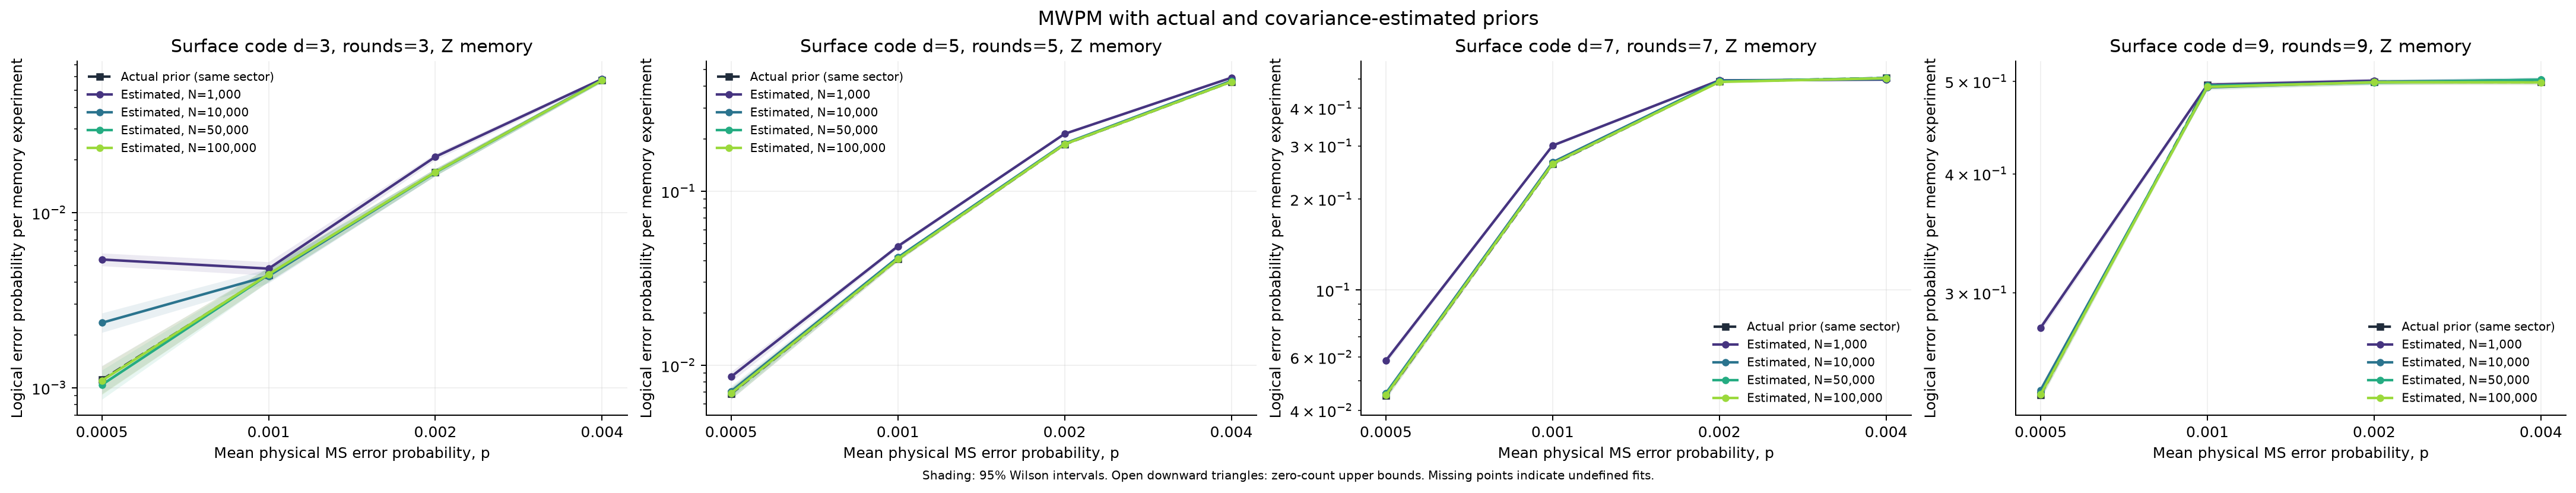

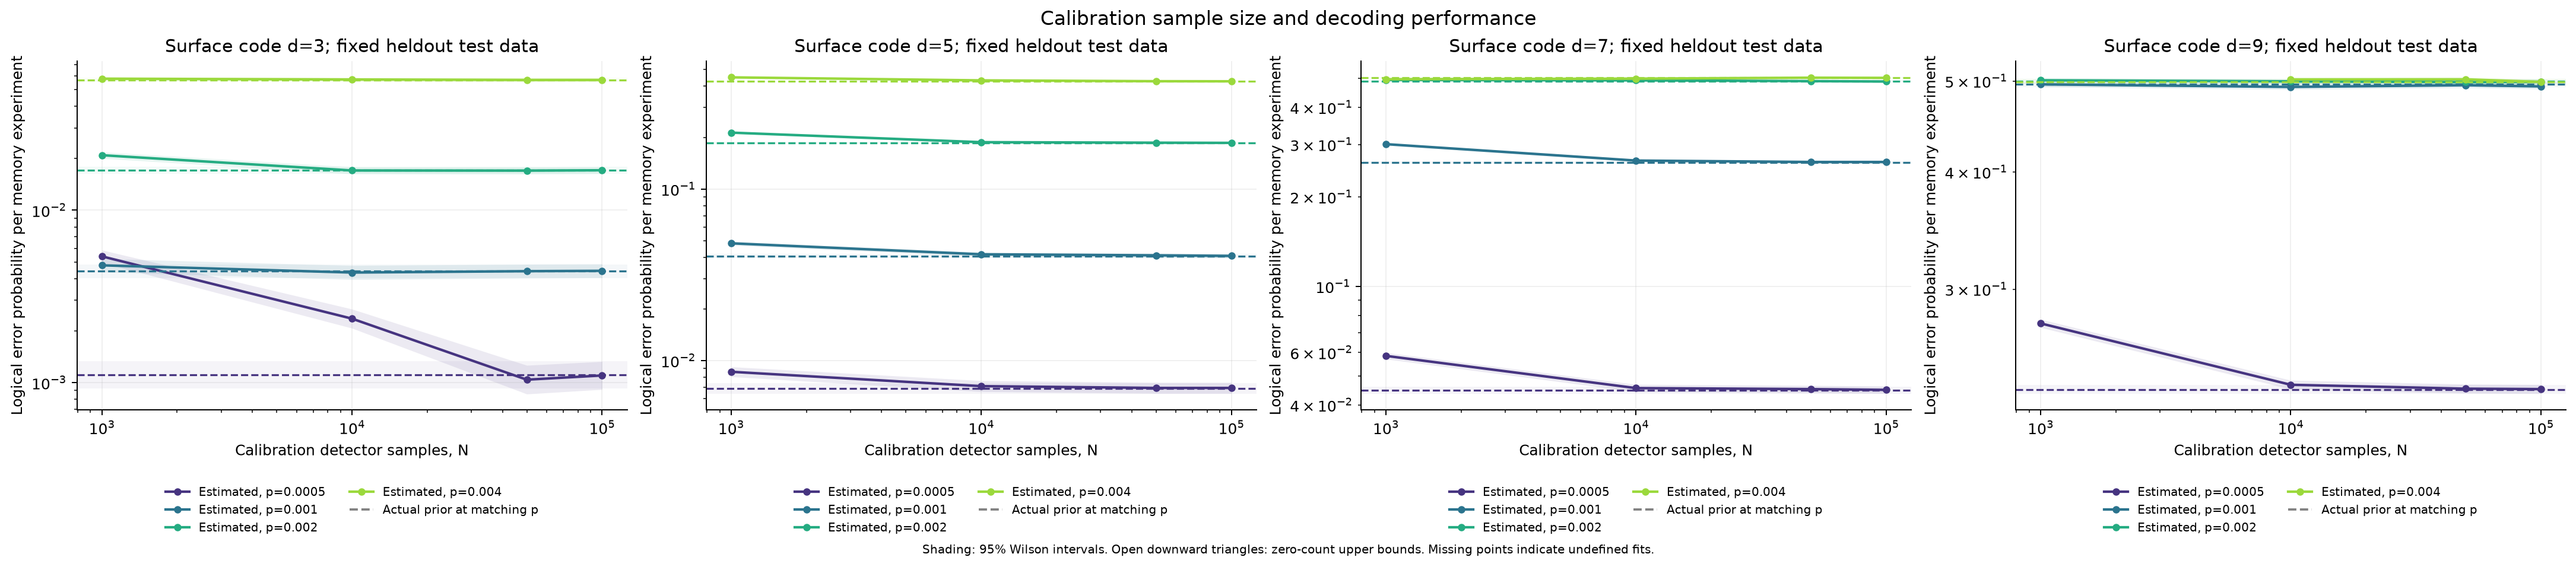

In [6]:
figure_paths = plot_results(OUT)
from IPython.display import Image
display(Image(filename=str(OUT / 'figures/ler_vs_physical_error.png')))
display(Image(filename=str(OUT / 'figures/ler_vs_calibration_shots.png')))


## 7. Inspect recovered priors and saved artifacts

The first two panels compare the actual pair-probability matrix and raw S11
matrix. The third compares pair and boundary priors. Negative correlations
remain visible in the raw matrix; floor-clipped decoder probabilities appear
on the floor line in the scatter plot. True priors are accessed only for this
post-fit comparison.


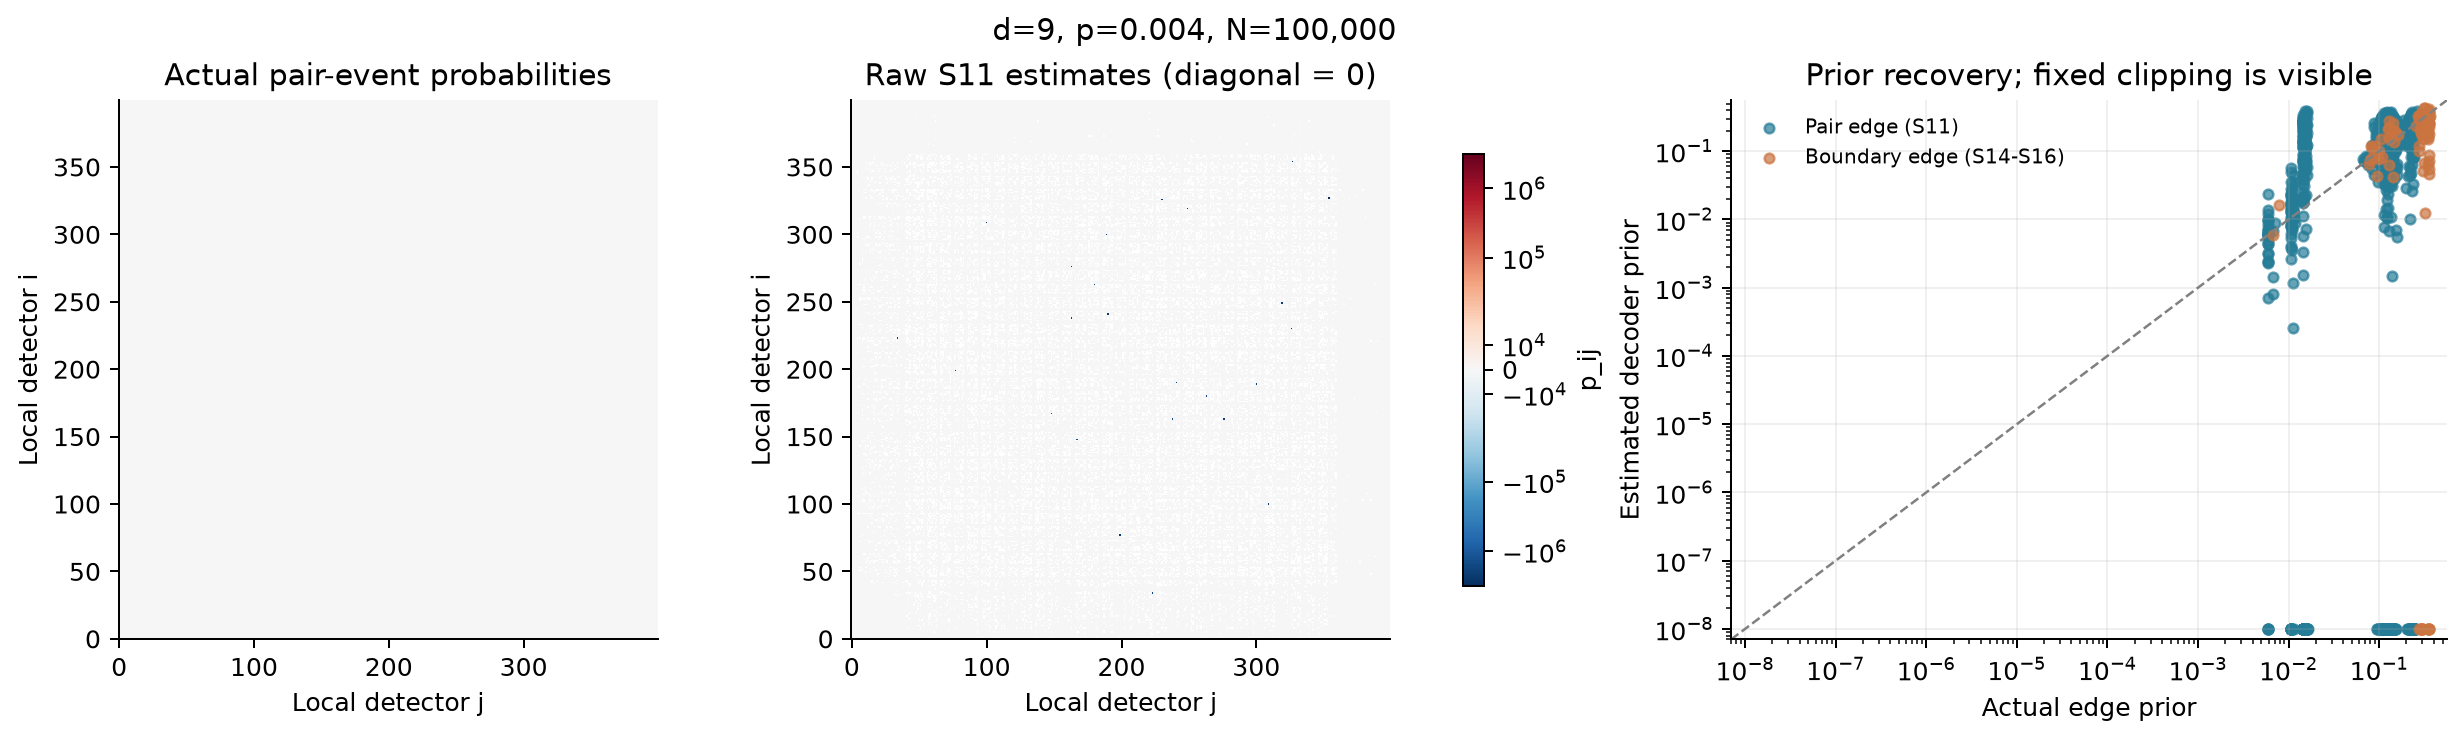

Prior error diagnostics: {'mean_absolute_error': 0.07843436824521195, 'root_mean_squared_error': 0.10714520286364869, 'max_absolute_error': 0.37949917684757634, 'num_edges': 1945}
Saved results: results/main1
Figures: ['ler_vs_physical_error.png', 'ler_vs_physical_error.pdf', 'ler_vs_calibration_shots.png', 'ler_vs_calibration_shots.pdf', 'priors_d3.png', 'priors_d3.pdf', 'priors_d5.png', 'priors_d5.pdf', 'priors_d7.png', 'priors_d7.pdf', 'priors_d9.png', 'priors_d9.pdf']
CSV tables: metrics.csv, paired_comparisons.csv, per-fit prior_comparison.csv
Undefined fits: results/main1/fit_skips.json


In [7]:
prior_figure = OUT / f'figures/priors_d{case.distance}.png'
if prior_figure in figure_paths:
    display(Image(filename=str(prior_figure)))
if (fit_dir / 'prior_error.json').is_file():
    print('Prior error diagnostics:', read_json(fit_dir / 'prior_error.json'))
print('Saved results:', OUT)
print('Figures:', [p.name for p in figure_paths])
print('CSV tables: metrics.csv, paired_comparisons.csv, per-fit prior_comparison.csv')
print('Undefined fits:', OUT / 'fit_skips.json')
